<a href="https://colab.research.google.com/github/kushagrapathak155/Ai-Based-Covis19-Detection_From-Lung-X-Ray/blob/main/FinalProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phishing Website Detection using Neural Network
The aim of the experiments conducted in this notebook is to give an idea of how modern _phishing website attacks_ can be prevented using machine learning. To do this, we are going to use the [Phishing Websites' Dataset](https://archive.ics.uci.edu/ml/datasets/phishing+websites).

Initially URLs from the dataset were broken down to numerical values using the file "Feature Extraction" which classifies and assigns values based on the research performed during the Capstone Project. Once that was done, every result was stored in a CSV file to be used here in this notebook.

We will start off the experiments by importing the initial set of Python modules.  

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Filter the uneccesary warnings
import warnings
warnings.filterwarnings("ignore")

# Import pandas and numpy
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import io
df = pd.read_csv('/content/drive/MyDrive/csv_result-Phishing_features (1).csv')

### Data loading and basic display

In [3]:
df.head()

,id,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [4]:
y = df['Result']

In [5]:
y=y.replace(-1,0)
y

0        0
1        0
2        0
3        0
4        1
        ..
11050    1
11051    0
11052    0
11053    0
11054    0
Name: Result, Length: 11055, dtype: int64

In [6]:
X = df.iloc[:,1:31]

In [7]:
X.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1


In [8]:
# Check for missing values
missing_values = X.isnull().sum()
print("Missing values:\n", missing_values)

Missing values:
 having_IP_Address              0
URL_Length                     0
Shortining_Service             0
having_At_Symbol               0
double_slash_redirecting       0
Prefix_Suffix                  0
having_Sub_Domain              0
SSLfinal_State                 0
Domain_registeration_length    0
Favicon                        0
port                           0
HTTPS_token                    0
Request_URL                    0
URL_of_Anchor                  0
Links_in_tags                  0
SFH                            0
Submitting_to_email            0
Abnormal_URL                   0
Redirect                       0
on_mouseover                   0
RightClick                     0
popUpWidnow                    0
Iframe                         0
age_of_domain                  0
DNSRecord                      0
web_traffic                    0
Page_Rank                      0
Google_Index                   0
Links_pointing_to_page         0
Statistical_report        

### Inspecting data dimensions and column names

In [9]:
# Data dimension
X.shape

(11055, 30)

In [ ]:
# Data columns
X.columns

Index(['having_IP_Address', 'URL_Length', 'Shortining_Service',
       'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix',
       'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length',
       'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor',
       'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL',
       'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe',
       'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank',
       'Google_Index', 'Links_pointing_to_page', 'Statistical_report'],
      dtype='object')

### Finding out the distribution of the class labels and preparing a report

In [10]:
from collections import Counter

classes = Counter(df['Result'].values)
classes.most_common()

[(1, 6157), (-1, 4898)]

In [11]:
class_dist = pd.DataFrame(classes.most_common(), columns=['Class', 'Num_Observations'])
class_dist

,Class,Num_Observations
0,1,6157
1,-1,4898


### Preparing a basic bar plot of the distribution of the class labels

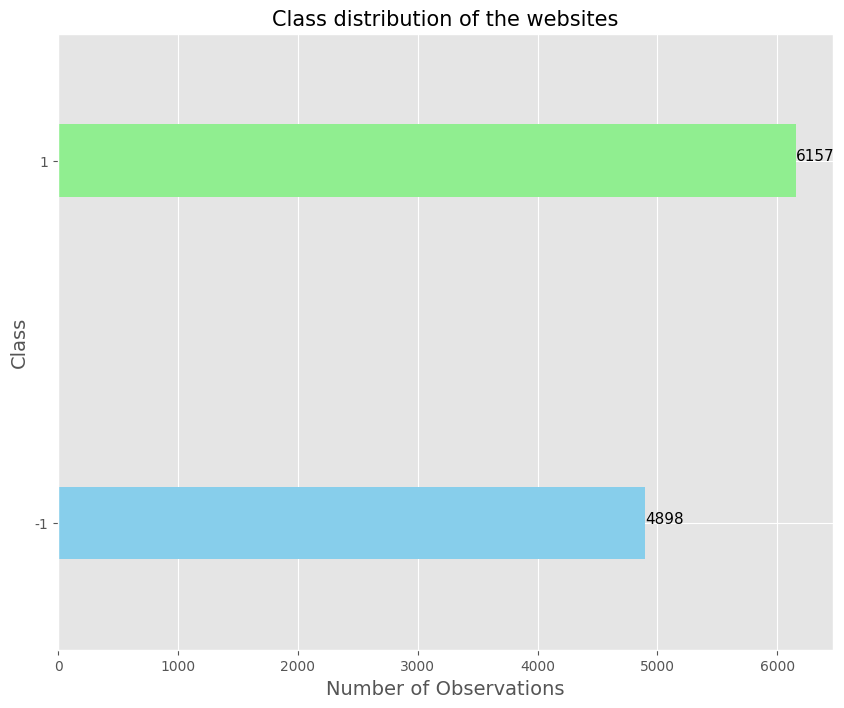

In [13]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('ggplot')

subplot = class_dist.groupby('Class')['Num_Observations'].sum().plot(kind='barh', width=0.2, figsize=(10,8),color=('skyblue','lightgreen'))

subplot.set_title('Class distribution of the websites', fontsize = 15)
subplot.set_xlabel('Number of Observations', fontsize = 14)
subplot.set_ylabel('Class', fontsize = 14)

for i in subplot.patches:
    subplot.text(i.get_width()+0.1, i.get_y()+0.1, \
                 str(i.get_width()), fontsize=11)

### Finding out the summary statistics from the data

In [14]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
having_IP_Address,11055.0,0.313795,0.949534,-1.0,-1.0,1.0,1.0,1.0
URL_Length,11055.0,-0.633198,0.766095,-1.0,-1.0,-1.0,-1.0,1.0
Shortining_Service,11055.0,0.738761,0.673998,-1.0,1.0,1.0,1.0,1.0
having_At_Symbol,11055.0,0.700588,0.713598,-1.0,1.0,1.0,1.0,1.0
double_slash_redirecting,11055.0,0.741474,0.671011,-1.0,1.0,1.0,1.0,1.0
Prefix_Suffix,11055.0,-0.734962,0.678139,-1.0,-1.0,-1.0,-1.0,1.0
having_Sub_Domain,11055.0,0.063953,0.817518,-1.0,-1.0,0.0,1.0,1.0
SSLfinal_State,11055.0,0.250927,0.911892,-1.0,-1.0,1.0,1.0,1.0
Domain_registeration_length,11055.0,-0.336771,0.941629,-1.0,-1.0,-1.0,1.0,1.0
Favicon,11055.0,0.628584,0.777777,-1.0,1.0,1.0,1.0,1.0


### Finding out the basic information of the columns present in the dataset

In [15]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   having_IP_Address            11055 non-null  int64
 1   URL_Length                   11055 non-null  int64
 2   Shortining_Service           11055 non-null  int64
 3   having_At_Symbol             11055 non-null  int64
 4   double_slash_redirecting     11055 non-null  int64
 5   Prefix_Suffix                11055 non-null  int64
 6   having_Sub_Domain            11055 non-null  int64
 7   SSLfinal_State               11055 non-null  int64
 8   Domain_registeration_length  11055 non-null  int64
 9   Favicon                      11055 non-null  int64
 10  port                         11055 non-null  int64
 11  HTTPS_token                  11055 non-null  int64
 12  Request_URL                  11055 non-null  int64
 13  URL_of_Anchor                11055 non-null  i

### Data splitting

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=1)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.33, random_state=1)

Data splitting graph representation

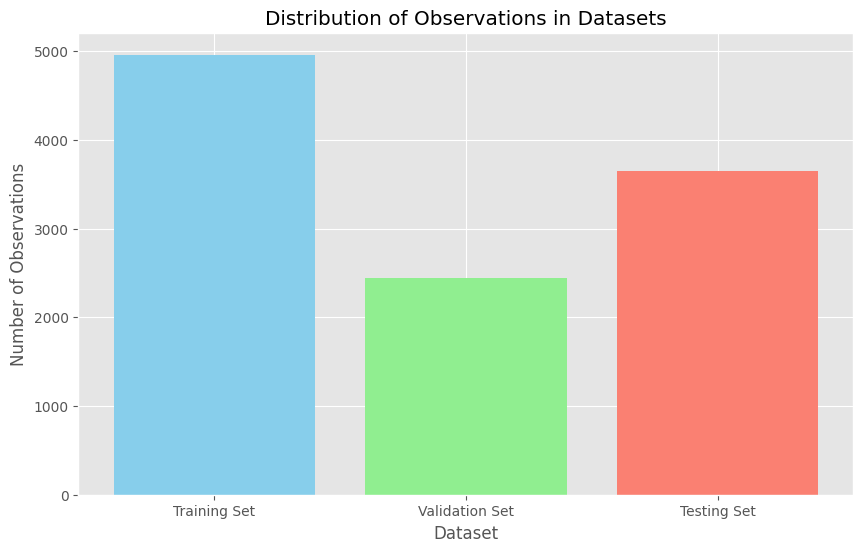

In [17]:
import matplotlib.pyplot as plt

# Create a bar plot to visualize the distribution of classes in each dataset
plt.figure(figsize=(10, 6))

# Define labels for the bars
labels = ['Training Set', 'Validation Set', 'Testing Set']

# Define the heights of the bars
heights = [len(y_train), len(y_val), len(y_test)]

# Define colors for the bars
colors = ['skyblue', 'lightgreen', 'salmon']

# Create the bar plot
plt.bar(labels, heights, color=colors)

# Add labels and title
plt.xlabel('Dataset')
plt.ylabel('Number of Observations')
plt.title('Distribution of Observations in Datasets')

# Show the plot
plt.show()


### Defining an EarlyStopping callback

In [18]:
from keras import callbacks

es_cb = callbacks.EarlyStopping(monitor='loss', min_delta=0.001, patience=5)

## Trying to improve the predictive performance with Neural Networks

### Model-1 with SGD Optimizer

In [19]:
import tensorflow as tf
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix

model = tf.keras.models.Sequential([
  tf.keras.layers.Dense(512, activation=tf.nn.relu),
  tf.keras.layers.Dense(512, activation=tf.nn.relu),
  tf.keras.layers.Dense(256, activation=tf.nn.relu),
  tf.keras.layers.Dense(1, activation=tf.nn.sigmoid)
])
model.compile(optimizer='sgd',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history_sgd1 = model.fit(X_train, y_train, epochs=15,batch_size=1,validation_data=(X_val, y_val),callbacks=[es_cb])
test_loss1, test_accuracy1 = model.evaluate(X_test, y_test)



# Predict labels for test data
y_pred_sgd = model.predict(X_test)
y_pred_binary_sgd = (y_pred_sgd > 0.5).astype(int)

# Calculate F1 score
f1_score_sgd = f1_score(y_test, y_pred_binary_sgd)

print("F1 Score (SGD):", f1_score_sgd)

# Calculate ROC AUC score for SGD optimizer
roc_auc_sgd = roc_auc_score(y_test, y_pred_sgd)
print("ROC AUC Score (SGD):", roc_auc_sgd)

# Calculate confusion matrix for SGD optimizer
cm_sgd = confusion_matrix(y_test, y_pred_binary_sgd)
print("Confusion Matrix (SGD):\n", cm_sgd)


Epoch 1/15
4962/4962 [==============================] - 26s 5ms/step - loss: 0.2198 - accuracy: 0.9146 - val_loss: 0.1618 - val_accuracy: 0.9341
Epoch 2/15
4962/4962 [==============================] - 27s 5ms/step - loss: 0.1562 - accuracy: 0.9359 - val_loss: 0.1524 - val_accuracy: 0.9415
Epoch 3/15
4962/4962 [==============================] - 26s 5ms/step - loss: 0.1314 - accuracy: 0.9430 - val_loss: 0.1482 - val_accuracy: 0.9468
Epoch 4/15
4962/4962 [==============================] - 25s 5ms/step - loss: 0.1212 - accuracy: 0.9504 - val_loss: 0.1272 - val_accuracy: 0.9448
Epoch 5/15
4962/4962 [==============================] - 23s 5ms/step - loss: 0.1071 - accuracy: 0.9541 - val_loss: 0.1240 - val_accuracy: 0.9480
Epoch 6/15
4962/4962 [==============================] - 26s 5ms/step - loss: 0.0939 - accuracy: 0.9607 - val_loss: 0.1345 - val_accuracy: 0.9427
Epoch 7/15
4962/4962 [==============================] - 27s 5ms/step - loss: 0.0902 - accuracy: 0.9617 - val_loss: 0.1209 - val_ac

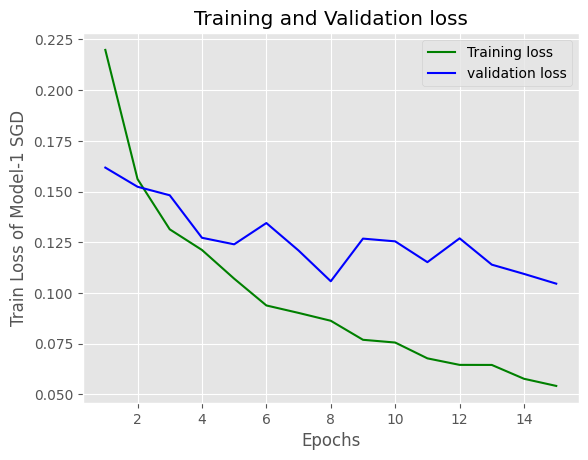

In [20]:
loss_train = history_sgd1.history['loss']
loss_val = history_sgd1.history['val_loss']
epochs = range(1,16)
plt.plot(epochs, loss_train, 'g', label='Training loss')
plt.plot(epochs, loss_val, 'b', label='validation loss')
plt.title('Training and Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Train Loss of Model-1 SGD')
plt.legend()
plt.show()

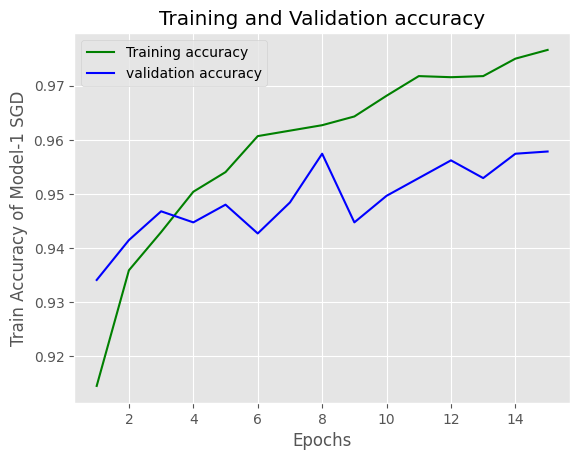

In [21]:
acc_train_sgd1 = history_sgd1.history['accuracy']
acc_val_sgd1 = history_sgd1.history['val_accuracy']
epochs = range(1,16)
plt.plot(epochs, acc_train_sgd1, 'g', label='Training accuracy')
plt.plot(epochs, acc_val_sgd1, 'b', label='validation accuracy')
plt.title('Training and Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Train Accuracy of Model-1 SGD')
plt.legend()
plt.show()

### Model-1 with RMSProp Optimizer

In [22]:
import tensorflow as tf
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix

model = tf.keras.models.Sequential([
  tf.keras.layers.Dense(512, activation=tf.nn.relu),
  tf.keras.layers.Dense(512, activation=tf.nn.relu),
  tf.keras.layers.Dense(256, activation=tf.nn.relu),
  tf.keras.layers.Dense(1, activation=tf.nn.sigmoid)
])
model.compile(optimizer='rmsprop',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history_rmsprop1 = model.fit(X_train, y_train, epochs=15,batch_size=1,validation_data=(X_val, y_val),callbacks=[es_cb])
test_loss2, test_accuracy2 = model.evaluate(X_test, y_test)

# Predict labels for test data
y_pred_rmsprop = model.predict(X_test)
y_pred_binary_rmsprop = (y_pred_rmsprop > 0.5).astype(int)

# Calculate F1 score
f1_score_rmsprop = f1_score(y_test, y_pred_binary_rmsprop)

print("F1 Score (RMSProp):", f1_score_rmsprop)

# Calculate ROC AUC score for RMSProp optimizer
roc_auc_rmsprop = roc_auc_score(y_test, y_pred_rmsprop)
print("ROC AUC Score (RMSProp):", roc_auc_rmsprop)

# Calculate confusion matrix for RMSProp optimizer
cm_rmsprop = confusion_matrix(y_test, y_pred_binary_rmsprop)
print("Confusion Matrix (RMSProp):\n", cm_rmsprop)

Epoch 1/15
4962/4962 [==============================] - 36s 7ms/step - loss: 0.2853 - accuracy: 0.9129 - val_loss: 0.3454 - val_accuracy: 0.9182
Epoch 2/15
4962/4962 [==============================] - 35s 7ms/step - loss: 0.2707 - accuracy: 0.9274 - val_loss: 0.2951 - val_accuracy: 0.9317
Epoch 3/15
4962/4962 [==============================] - 32s 7ms/step - loss: 0.2562 - accuracy: 0.9355 - val_loss: 0.3862 - val_accuracy: 0.9313
Epoch 4/15
4962/4962 [==============================] - 35s 7ms/step - loss: 0.2355 - accuracy: 0.9410 - val_loss: 0.2205 - val_accuracy: 0.9337
Epoch 5/15
4962/4962 [==============================] - 34s 7ms/step - loss: 0.2310 - accuracy: 0.9448 - val_loss: 0.2891 - val_accuracy: 0.9313
Epoch 6/15
4962/4962 [==============================] - 31s 6ms/step - loss: 0.2244 - accuracy: 0.9418 - val_loss: 0.1528 - val_accuracy: 0.9423
Epoch 7/15
4962/4962 [==============================] - 32s 6ms/step - loss: 0.2135 - accuracy: 0.9458 - val_loss: 0.3949 - val_ac

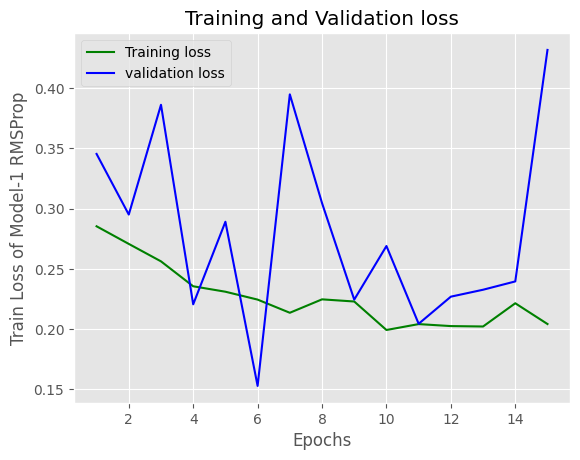

In [23]:
loss_train = history_rmsprop1.history['loss']
loss_val = history_rmsprop1.history['val_loss']
epochs = range(1,16)
plt.plot(epochs, loss_train, 'g', label='Training loss')
plt.plot(epochs, loss_val, 'b', label='validation loss')
plt.title('Training and Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Train Loss of Model-1 RMSProp')
plt.legend()
plt.show()

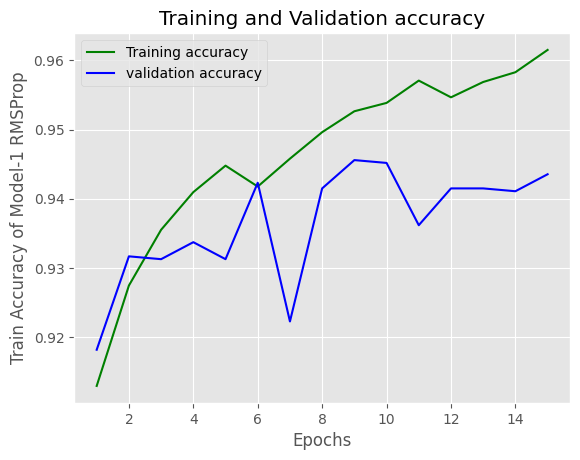

In [24]:
acc_train_rmsprop1 = history_rmsprop1.history['accuracy']
acc_val_rmsprop1 = history_rmsprop1.history['val_accuracy']
epochs = range(1,16)
plt.plot(epochs, acc_train_rmsprop1, 'g', label='Training accuracy')
plt.plot(epochs, acc_val_rmsprop1, 'b', label='validation accuracy')
plt.title('Training and Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Train Accuracy of Model-1 RMSProp')
plt.legend()
plt.show()

### Model-1 with Adam Optimizer

In [25]:
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, confusion_matrix

model = tf.keras.models.Sequential([
  tf.keras.layers.Dense(512, activation=tf.nn.relu),
  tf.keras.layers.Dense(512, activation=tf.nn.relu),
  tf.keras.layers.Dense(256, activation=tf.nn.relu),
  tf.keras.layers.Dense(1, activation=tf.nn.sigmoid)
])
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history_adam1 = model.fit(X_train, y_train, epochs=15,batch_size=1,validation_data=(X_val, y_val),callbacks=[es_cb])
test_loss3, test_accuracy3 = model.evaluate(X_test, y_test)



# Predict labels for test data
y_pred_adam = model.predict(X_test)
y_pred_binary_adam = (y_pred_adam > 0.5).astype(int)

# Calculate F1 score
f1_score_adam = f1_score(y_test, y_pred_binary_adam)

print("F1 Score (Adam):", f1_score_adam)


# Calculate ROC AUC score for Adam optimizer
roc_auc_adam = roc_auc_score(y_test, y_pred_adam)

# Calculate confusion matrix for Adam optimizer
cm_adam = confusion_matrix(y_test, y_pred_binary_adam)

print("ROC AUC Score (Adam):", roc_auc_adam)
print("Confusion Matrix (Adam):\n", cm_adam)

Epoch 1/15
4962/4962 [==============================] - 46s 9ms/step - loss: 0.2199 - accuracy: 0.9172 - val_loss: 0.1765 - val_accuracy: 0.9321
Epoch 2/15
4962/4962 [==============================] - 34s 7ms/step - loss: 0.1720 - accuracy: 0.9351 - val_loss: 0.1605 - val_accuracy: 0.9333
Epoch 3/15
4962/4962 [==============================] - 38s 8ms/step - loss: 0.1638 - accuracy: 0.9353 - val_loss: 0.1740 - val_accuracy: 0.9370
Epoch 4/15
4962/4962 [==============================] - 50s 10ms/step - loss: 0.1439 - accuracy: 0.9432 - val_loss: 0.1699 - val_accuracy: 0.9309
Epoch 5/15
4962/4962 [==============================] - 35s 7ms/step - loss: 0.1321 - accuracy: 0.9448 - val_loss: 0.1652 - val_accuracy: 0.9206
Epoch 6/15
4962/4962 [==============================] - 34s 7ms/step - loss: 0.1195 - accuracy: 0.9496 - val_loss: 0.1396 - val_accuracy: 0.9407
Epoch 7/15
4962/4962 [==============================] - 37s 7ms/step - loss: 0.1169 - accuracy: 0.9528 - val_loss: 0.1459 - val_a

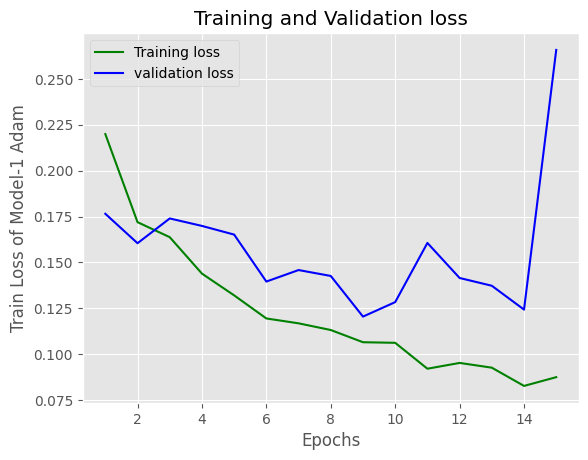

In [26]:
loss_train = history_adam1.history['loss']
loss_val = history_adam1.history['val_loss']
epochs = range(1,16)
plt.plot(epochs, loss_train, 'g', label='Training loss')
plt.plot(epochs, loss_val, 'b', label='validation loss')
plt.title('Training and Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Train Loss of Model-1 Adam')
plt.legend()
plt.show()

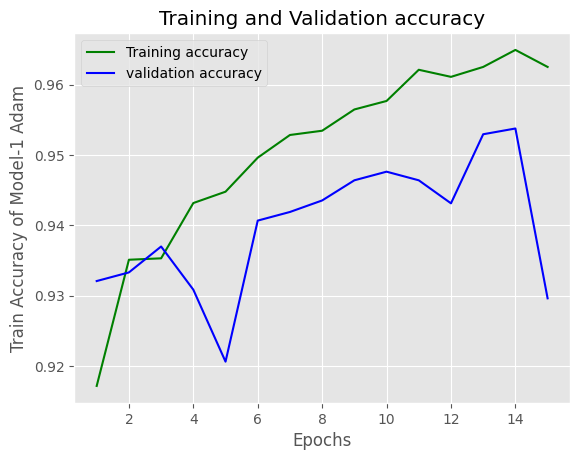

In [27]:
acc_train_adam1 = history_adam1.history['accuracy']
acc_val_adam1 = history_adam1.history['val_accuracy']
epochs = range(1,16)
plt.plot(epochs, acc_train_adam1, 'g', label='Training accuracy')
plt.plot(epochs, acc_val_adam1, 'b', label='validation accuracy')
plt.title('Training and Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Train Accuracy of Model-1 Adam')
plt.legend()
plt.show()

### Comparision between Optimizer for Model-1

In [28]:
test_accuracies = [test_accuracy1, test_accuracy2, test_accuracy3]
optimizers = ['SGD', 'RMSprop', 'Adam']

#### Test Accurcy

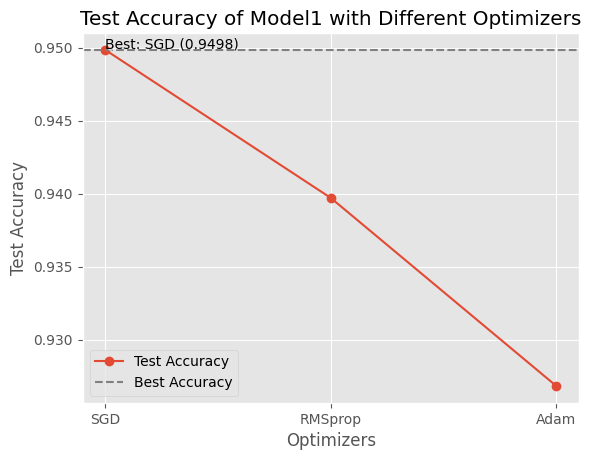

In [29]:
# Plotting
plt.plot(optimizers, test_accuracies, marker='o', linestyle='-', label='Test Accuracy')
plt.axhline(max(test_accuracies), color='gray', linestyle='--', label='Best Accuracy')

# Annotate the optimizer with the highest test accuracy
best_optimizer_index = test_accuracies.index(max(test_accuracies))
best_optimizer = optimizers[best_optimizer_index]
best_accuracy = test_accuracies[best_optimizer_index]
offset = 0.0001  # Adjust the offset as needed
plt.annotate(f'Best: {best_optimizer} ({best_accuracy:.4f})',
             xy=(best_optimizer, best_accuracy),
             xytext=(best_optimizer, best_accuracy + offset),
             arrowprops=dict(facecolor='black', arrowstyle='->', mutation_scale=5))

# Add title and labels
plt.title('Test Accuracy of Model1 with Different Optimizers')
plt.xlabel('Optimizers')
plt.ylabel('Test Accuracy')
plt.grid(True)
plt.legend()

# Display the plot
plt.show()





#### F1 Score

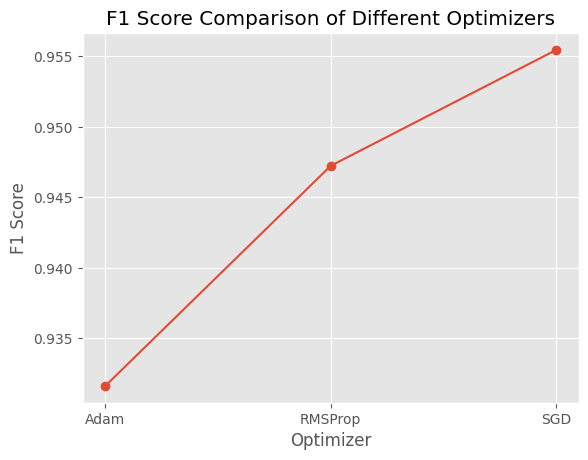

In [30]:
import matplotlib.pyplot as plt

# Optimizers
optimizers = ['Adam', 'RMSProp', 'SGD']

# F1 scores
f1_scores = [f1_score_adam, f1_score_rmsprop, f1_score_sgd]

# Create line plot
plt.plot(optimizers, f1_scores, marker='o', linestyle='-')

# Add labels and title
plt.xlabel('Optimizer')
plt.ylabel('F1 Score')
plt.title('F1 Score Comparison of Different Optimizers')

# Show plot
plt.grid(True)
plt.show()





#### ROC AUC Score

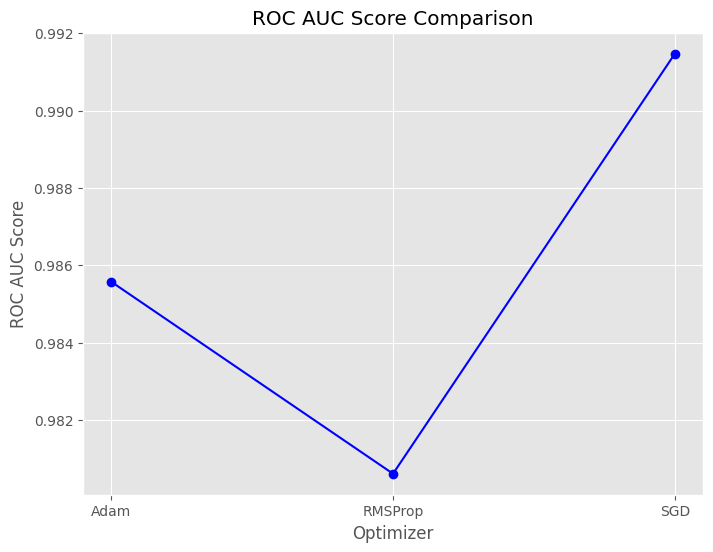

In [31]:
import matplotlib.pyplot as plt

# Define the ROC AUC scores for each optimizer
roc_auc_scores = [roc_auc_adam, roc_auc_rmsprop, roc_auc_sgd]
optimizers = ['Adam', 'RMSProp', 'SGD']

# Plot ROC AUC scores using a line plot
plt.figure(figsize=(8, 6))
plt.plot(optimizers, roc_auc_scores, marker='o', linestyle='-', color='b')
plt.xlabel('Optimizer')
plt.ylabel('ROC AUC Score')
plt.title('ROC AUC Score Comparison')
plt.grid(True)
plt.show()







#### Confusion Matrix

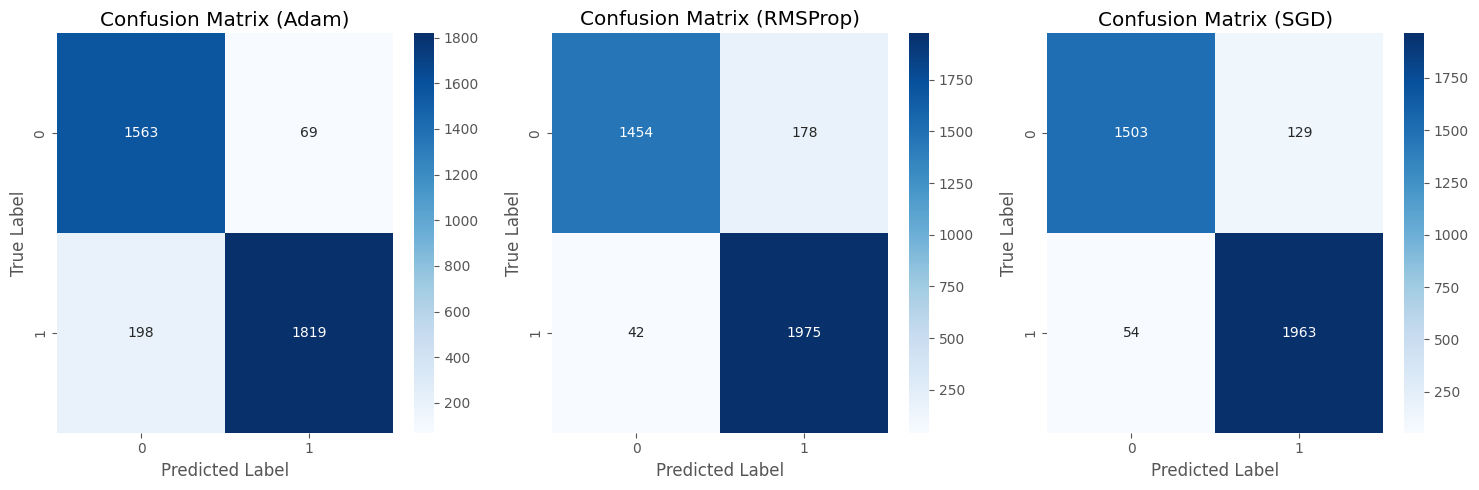

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Define the confusion matrices for each optimizer
cms = [cm_adam, cm_rmsprop, cm_sgd]
optimizers = ['Adam', 'RMSProp', 'SGD']

# Create subplots for confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Loop through each optimizer and plot its confusion matrix
for i, (cm, optimizer) in enumerate(zip(cms, optimizers)):
    sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', ax=axes[i])
    axes[i].set_title(f'Confusion Matrix ({optimizer})')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()


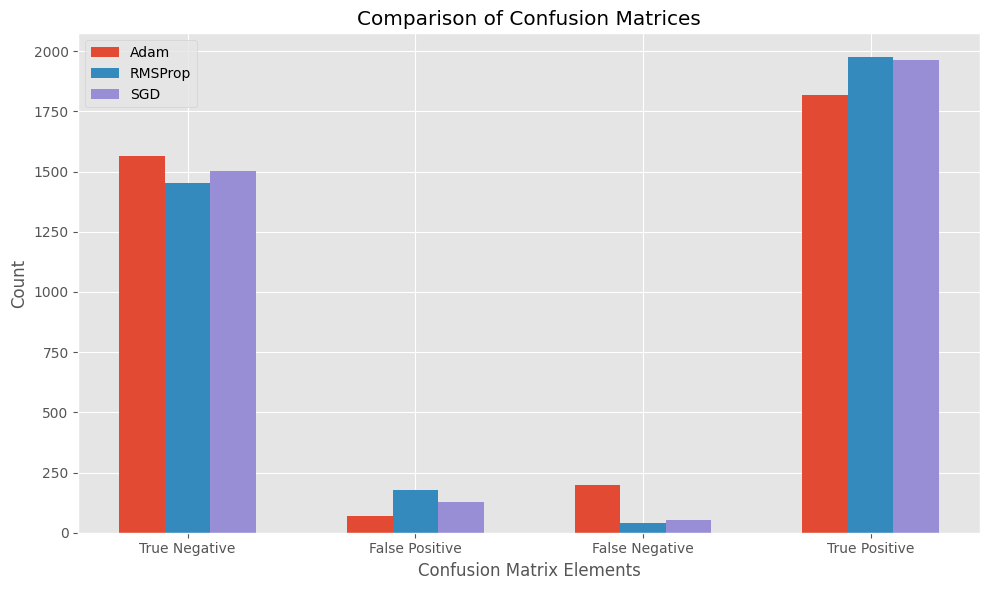

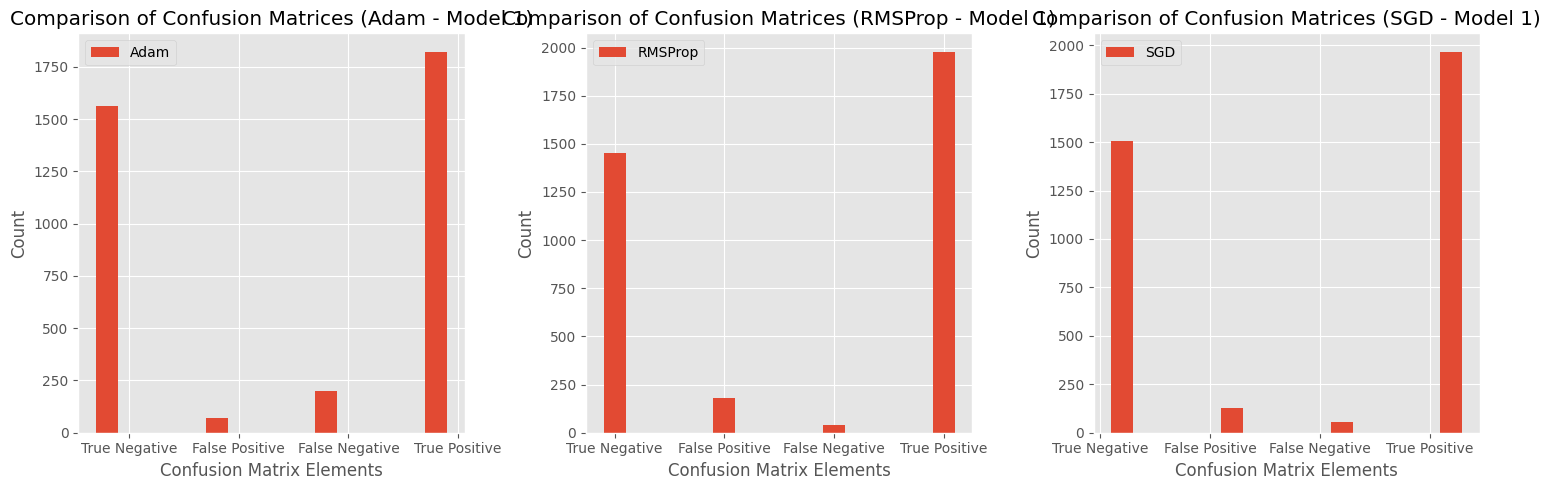

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# Define the confusion matrices for each optimizer
cms = [cm_adam, cm_rmsprop, cm_sgd]
optimizers = ['Adam', 'RMSProp', 'SGD']

# Define the labels for true and predicted classes
labels = ['True Negative', 'False Positive', 'False Negative', 'True Positive']

# Define the positions for the bars
x = np.arange(len(labels))

# Define the width of the bars
width = 0.2

# Create grouped bar chart for confusion matrices
fig, ax = plt.subplots(figsize=(10, 6))

for i, (cm, optimizer) in enumerate(zip(cms, optimizers)):
    ax.bar(x + i * width, cm.flatten(), width=width, label=optimizer)

# Add labels, title, and legend
ax.set_xlabel('Confusion Matrix Elements')
ax.set_ylabel('Count')
ax.set_title('Comparison of Confusion Matrices')
ax.set_xticks(x + width)
ax.set_xticklabels(labels)
ax.legend()

plt.tight_layout()
plt.show()

# Define the confusion matrices for each optimizer for Model 2
cms_model1 = [cm_adam, cm_rmsprop, cm_sgd]
optimizers_model1 = ['Adam', 'RMSProp', 'SGD']

# Create subplots for confusion matrices of Model 2
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Loop through each optimizer and plot its confusion matrix for Model 2
for i, (cm, optimizer) in enumerate(zip(cms_model1, optimizers_model1)):
    axes[i].bar(x + i * width, cm.flatten(), width=width, label=optimizer)
    axes[i].set_xlabel('Confusion Matrix Elements')
    axes[i].set_ylabel('Count')
    axes[i].set_title(f'Comparison of Confusion Matrices ({optimizer} - Model 1)')
    axes[i].set_xticks(x + width)
    axes[i].set_xticklabels(labels)
    axes[i].legend()

plt.tight_layout()
plt.show()


#### Final Conclusion For Model 1

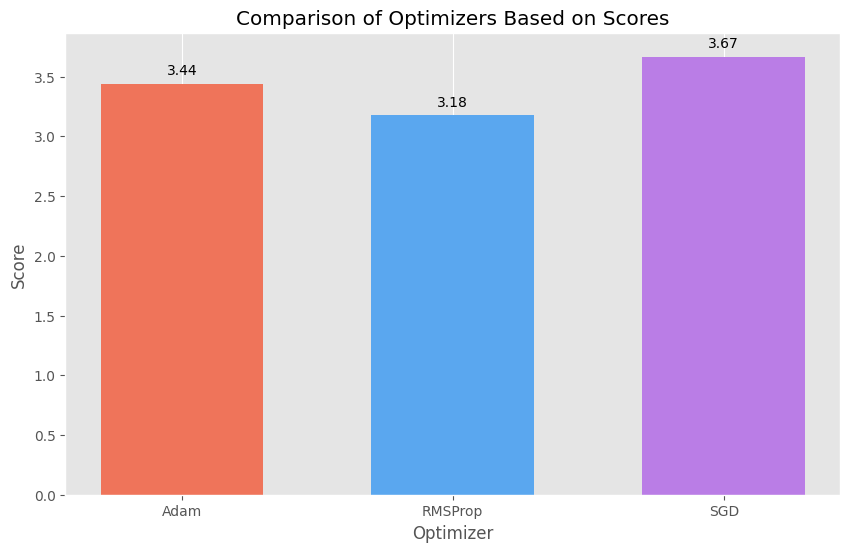

Best Optimizer: SGD


In [34]:
import matplotlib.pyplot as plt

# Define a scoring function
def score_optimizer(accuracy, f1, roc_auc, cm, test_loss):
    # Normalize confusion matrix values
    normalized_cm = cm / cm.sum()

    tp = normalized_cm[1, 1]  # Normalized True Positives
    tn = normalized_cm[0, 0]  # Normalized True Negatives
    fp = normalized_cm[0, 1]  # Normalized False Positives
    fn = normalized_cm[1, 0]  # Normalized False Negatives

    # Compute the score
    score = accuracy + f1 + roc_auc + (tp + tn - fp - fn) - test_loss
    return score

# Compute scores for each optimizer
score_adam = score_optimizer(test_accuracy3, f1_score_adam, roc_auc_adam, cm_adam, test_loss3)
score_rmsprop = score_optimizer(test_accuracy2, f1_score_rmsprop, roc_auc_rmsprop, cm_rmsprop, test_loss2)
score_sgd = score_optimizer(test_accuracy1, f1_score_sgd, roc_auc_sgd, cm_sgd, test_loss1)

# Create a bar plot to compare scores
optimizers = ['Adam', 'RMSProp', 'SGD']
scores = [score_adam, score_rmsprop, score_sgd]

plt.figure(figsize=(10, 6))
bars = plt.bar(optimizers, scores, color=['#EF745A', '#5AA7EF', '#BA7DE6'], width=0.6)  # Reduced width
plt.xlabel('Optimizer')
plt.ylabel('Score')
plt.title('Comparison of Optimizers Based on Scores')
plt.ylim(0, max(scores) + 0.2)  # Set y-axis limit
plt.grid(axis='y')

# Add text labels on top of each bar
for bar, score in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05, round(score, 2),
             ha='center', va='bottom')

plt.show()

# Choose the optimizer with the highest score
best_optimizer = optimizers[scores.index(max(scores))]
print("Best Optimizer:", best_optimizer)





### Model-2 with SGD Optimizer

### Here in Model-2, as we are increasing the number of neurons, we are also using dropout to overcome overfitting

In [35]:
import tensorflow as tf
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix

# Define Model 2 architecture
model2 = tf.keras.models.Sequential([
    tf.keras.layers.Dense(512, activation=tf.nn.relu),
    tf.keras.layers.Dense(512, activation=tf.nn.relu),
    tf.keras.layers.Dense(1024, activation=tf.nn.relu),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation=tf.nn.sigmoid)
])

# Compile Model 2 with SGD optimizer
model2.compile(optimizer='sgd',
               loss='binary_crossentropy',
               metrics=['accuracy'])

# Train Model 2
history_sgd2 = model2.fit(X_train, y_train, epochs=15, batch_size=1, validation_data=(X_val, y_val), callbacks=[es_cb])

# Evaluate Model 2 on test data
test_loss21, test_accuracy21 = model2.evaluate(X_test, y_test)

# Predict labels for test data using Model 2
y_pred_sgd2 = model2.predict(X_test)
y_pred_binary_sgd2 = (y_pred_sgd2 > 0.5).astype(int)

# Calculate F1 score for Model 2
f1_score_sgd2 = f1_score(y_test, y_pred_binary_sgd2)

# Calculate ROC AUC score for Model 2
roc_auc_sgd2 = roc_auc_score(y_test, y_pred_sgd2)

# Calculate confusion matrix for Model 2
cm_sgd2 = confusion_matrix(y_test, y_pred_binary_sgd2)

# Print evaluation metrics for Model 2
print("Test Loss (Model 2 - SGD):", test_loss21)
print("Test Accuracy (Model 2 - SGD):", test_accuracy21)
print("F1 Score (Model 2 - SGD):", f1_score_sgd2)
print("ROC AUC Score (Model 2 - SGD):", roc_auc_sgd2)
print("Confusion Matrix (Model 2 - SGD):\n", cm_sgd2)



Epoch 1/15
4962/4962 [==============================] - 34s 7ms/step - loss: 0.2189 - accuracy: 0.9115 - val_loss: 0.1724 - val_accuracy: 0.9292
Epoch 2/15
4962/4962 [==============================] - 33s 7ms/step - loss: 0.1557 - accuracy: 0.9381 - val_loss: 0.1750 - val_accuracy: 0.9284
Epoch 3/15
4962/4962 [==============================] - 32s 6ms/step - loss: 0.1385 - accuracy: 0.9426 - val_loss: 0.1655 - val_accuracy: 0.9317
Epoch 4/15
4962/4962 [==============================] - 31s 6ms/step - loss: 0.1237 - accuracy: 0.9484 - val_loss: 0.1489 - val_accuracy: 0.9362
Epoch 5/15
4962/4962 [==============================] - 33s 7ms/step - loss: 0.1099 - accuracy: 0.9545 - val_loss: 0.1368 - val_accuracy: 0.9456
Epoch 6/15
4962/4962 [==============================] - 32s 6ms/step - loss: 0.1022 - accuracy: 0.9587 - val_loss: 0.1180 - val_accuracy: 0.9472
Epoch 7/15
4962/4962 [==============================] - 32s 6ms/step - loss: 0.0959 - accuracy: 0.9593 - val_loss: 0.1301 - val_ac

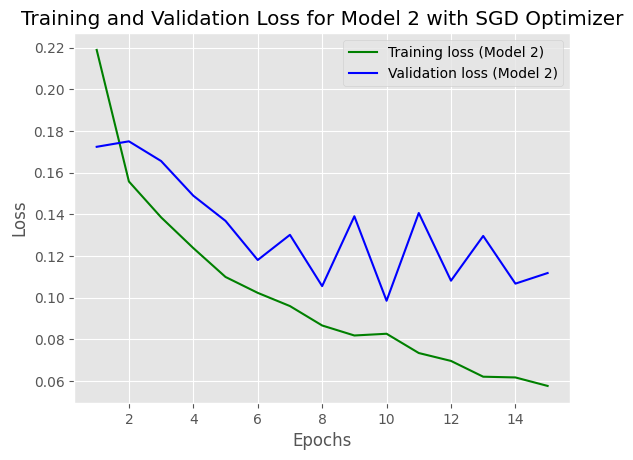

In [36]:
# Get the training and validation loss for Model 2
loss_train_model2 = history_sgd2.history['loss']
loss_val_model2 = history_sgd2.history['val_loss']

# Define the epochs
epochs = range(1, 16)

# Plot the training and validation loss for Model 2
plt.plot(epochs, loss_train_model2, 'g', label='Training loss (Model 2)')
plt.plot(epochs, loss_val_model2, 'b', label='Validation loss (Model 2)')
plt.title('Training and Validation Loss for Model 2 with SGD Optimizer')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()



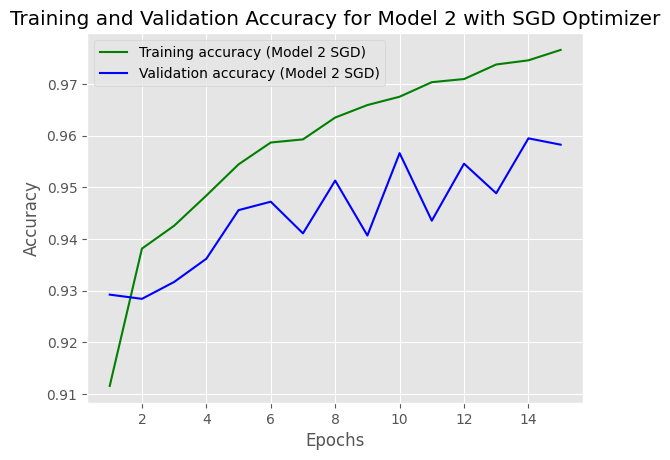

In [37]:
# Get the training and validation accuracy for Model 2 with SGD optimizer
acc_train_sgd2 = history_sgd2.history['accuracy']
acc_val_sgd2 = history_sgd2.history['val_accuracy']

# Plot the training and validation accuracy for Model 2 with SGD optimizer
plt.plot(epochs, acc_train_sgd2, 'g', label='Training accuracy (Model 2 SGD)')
plt.plot(epochs, acc_val_sgd2, 'b', label='Validation accuracy (Model 2 SGD)')
plt.title('Training and Validation Accuracy for Model 2 with SGD Optimizer')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()



### Model-2 with RMSProp Optimizer

In [41]:
import tensorflow as tf
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix

# Define Model 2 architecture
model2 = tf.keras.models.Sequential([
    tf.keras.layers.Dense(512, activation=tf.nn.relu),
    tf.keras.layers.Dense(512, activation=tf.nn.relu),
    tf.keras.layers.Dense(1024, activation=tf.nn.relu),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation=tf.nn.sigmoid)
])

# Compile Model 2 with RMSprop optimizer
model2.compile(optimizer='rmsprop',
               loss='binary_crossentropy',
               metrics=['accuracy'])

# Train Model 2
history_rmsprop2 = model2.fit(X_train, y_train, epochs=15, batch_size=1, validation_data=(X_val, y_val), callbacks=[es_cb])

# Evaluate Model 2 on test data
test_loss22, test_accuracy22 = model2.evaluate(X_test, y_test)

# Predict labels for test data using Model 2
y_pred_rmsprop2 = model2.predict(X_test)
y_pred_binary_rmsprop2 = (y_pred_rmsprop2 > 0.5).astype(int)

# Calculate F1 score for Model 2
f1_score_rmsprop2 = f1_score(y_test, y_pred_binary_rmsprop2)

# Calculate ROC AUC score for Model 2
roc_auc_rmsprop2 = roc_auc_score(y_test, y_pred_rmsprop2)

# Calculate confusion matrix for Model 2
cm_rmsprop2 = confusion_matrix(y_test, y_pred_binary_rmsprop2)

# Print evaluation metrics for Model 2
print("Test Loss (Model 2 - RMSProp):", test_loss22)
print("Test Accuracy (Model 2 - RMSProp):", test_accuracy22)
print("F1 Score (Model 2 - RMSProp):", f1_score_rmsprop2)
print("ROC AUC Score (Model 2 - RMSProp):", roc_auc_rmsprop2)
print("Confusion Matrix (Model 2 - RMSProp):\n", cm_rmsprop2)


Epoch 1/15
4962/4962 [==============================] - 83s 17ms/step - loss: 0.3137 - accuracy: 0.9166 - val_loss: 0.2013 - val_accuracy: 0.9341
Epoch 2/15
4962/4962 [==============================] - 52s 11ms/step - loss: 0.2838 - accuracy: 0.9291 - val_loss: 0.1985 - val_accuracy: 0.9288
Epoch 3/15
4962/4962 [==============================] - 52s 11ms/step - loss: 0.2584 - accuracy: 0.9333 - val_loss: 0.2357 - val_accuracy: 0.9317
Epoch 4/15
4962/4962 [==============================] - 54s 11ms/step - loss: 0.2526 - accuracy: 0.9391 - val_loss: 0.3607 - val_accuracy: 0.9309
Epoch 5/15
4962/4962 [==============================] - 52s 11ms/step - loss: 0.2560 - accuracy: 0.9426 - val_loss: 0.2235 - val_accuracy: 0.9431
Epoch 6/15
4962/4962 [==============================] - 53s 11ms/step - loss: 0.2440 - accuracy: 0.9428 - val_loss: 0.6006 - val_accuracy: 0.9444
Epoch 7/15
4962/4962 [==============================] - 52s 10ms/step - loss: 0.2449 - accuracy: 0.9430 - val_loss: 0.2201 -

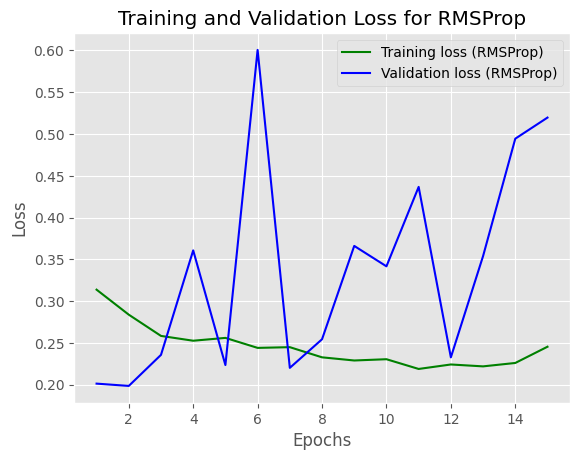

In [45]:
# Get the training and validation loss for RMSProp model
loss_train_rmsprop2 = history_rmsprop2.history['loss']
loss_val_rmsprop2 = history_rmsprop2.history['val_loss']

# Define the epochs
epochs = range(1, 16)

# Plot the training and validation loss for RMSProp model
plt.plot(epochs, loss_train_rmsprop2, 'g', label='Training loss (RMSProp)')
plt.plot(epochs, loss_val_rmsprop2, 'b', label='Validation loss (RMSProp)')
plt.title('Training and Validation Loss for RMSProp')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()



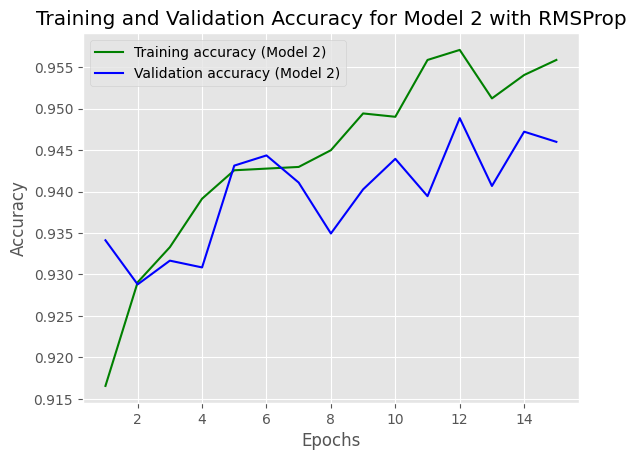

In [46]:
# Get the training and validation accuracy for Model 2 with RMSProp optimizer
acc_train_rmsprop2 = history_rmsprop2.history['accuracy']
acc_val_rmsprop2 = history_rmsprop2.history['val_accuracy']
epochs = range(1, 16)

# Plot the training and validation accuracy for Model 2 with RMSProp optimizer
plt.plot(epochs, acc_train_rmsprop2, 'g', label='Training accuracy (Model 2)')
plt.plot(epochs, acc_val_rmsprop2, 'b', label='Validation accuracy (Model 2)')
plt.title('Training and Validation Accuracy for Model 2 with RMSProp')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()



### Model-2 with Adam Optimizer

In [42]:
import tensorflow as tf
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
# Define Model 2 architecture
model2 = tf.keras.models.Sequential([
    tf.keras.layers.Dense(512, activation=tf.nn.relu),
    tf.keras.layers.Dense(512, activation=tf.nn.relu),
    tf.keras.layers.Dense(1024, activation=tf.nn.relu),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation=tf.nn.sigmoid)
])

# Compile Model 2
model2.compile(optimizer='adam',
               loss='binary_crossentropy',
               metrics=['accuracy'])

# Train Model 2 with Adam optimizer
history_adam2 = model2.fit(X_train, y_train, epochs=15, batch_size=1, validation_data=(X_val, y_val), callbacks=[es_cb])

# Evaluate Model 2 on test data with Adam optimizer
test_loss2_adam, test_accuracy2_adam = model2.evaluate(X_test, y_test)

# Predict labels for test data using Model 2 with Adam optimizer
y_pred_adam2 = model2.predict(X_test)
y_pred_binary_adam2 = (y_pred_adam2 > 0.5).astype(int)

# Calculate F1 score for Model 2 with Adam optimizer
f1_score_adam2 = f1_score(y_test, y_pred_binary_adam2)

# Calculate ROC AUC score for Model 2 with Adam optimizer
roc_auc_adam2 = roc_auc_score(y_test, y_pred_adam2)

# Calculate confusion matrix for Model 2 with Adam optimizer
cm_adam2 = confusion_matrix(y_test, y_pred_binary_adam2)

# Print evaluation metrics for Model 2 with Adam optimizer
print("Test Loss (Model 2 - Adam):", test_loss2_adam)
print("Test Accuracy (Model 2 - Adam):", test_accuracy2_adam)
print("F1 Score (Model 2 - Adam):", f1_score_adam2)
print("ROC AUC Score (Model 2 - Adam):", roc_auc_adam2)
print("Confusion Matrix (Model 2 - Adam):\n", cm_adam2)


Epoch 1/15
4962/4962 [==============================] - 58s 11ms/step - loss: 0.2383 - accuracy: 0.9123 - val_loss: 0.1642 - val_accuracy: 0.9358
Epoch 2/15
4962/4962 [==============================] - 57s 11ms/step - loss: 0.1990 - accuracy: 0.9299 - val_loss: 0.1638 - val_accuracy: 0.9329
Epoch 3/15
4962/4962 [==============================] - 56s 11ms/step - loss: 0.1683 - accuracy: 0.9345 - val_loss: 0.2906 - val_accuracy: 0.8850
Epoch 4/15
4962/4962 [==============================] - 62s 12ms/step - loss: 0.1578 - accuracy: 0.9428 - val_loss: 0.1776 - val_accuracy: 0.9366
Epoch 5/15
4962/4962 [==============================] - 56s 11ms/step - loss: 0.1467 - accuracy: 0.9444 - val_loss: 0.1843 - val_accuracy: 0.9259
Epoch 6/15
4962/4962 [==============================] - 57s 12ms/step - loss: 0.1348 - accuracy: 0.9488 - val_loss: 0.2030 - val_accuracy: 0.9419
Epoch 7/15
4962/4962 [==============================] - 57s 11ms/step - loss: 0.1365 - accuracy: 0.9502 - val_loss: 0.1748 -

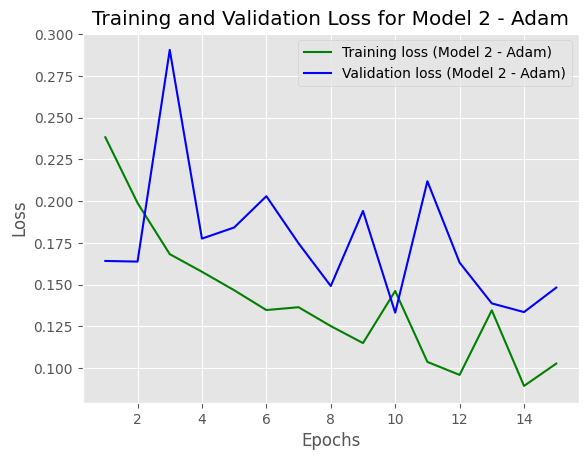

In [43]:
# Get the training and validation loss for Model 2 with Adam optimizer
loss_train_model2_adam = history_adam2.history['loss']
loss_val_model2_adam = history_adam2.history['val_loss']

# Define the epochs
epochs = range(1, 16)

# Plot the training and validation loss for Model 2 with Adam optimizer
plt.plot(epochs, loss_train_model2_adam, 'g', label='Training loss (Model 2 - Adam)')
plt.plot(epochs, loss_val_model2_adam, 'b', label='Validation loss (Model 2 - Adam)')
plt.title('Training and Validation Loss for Model 2 - Adam')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


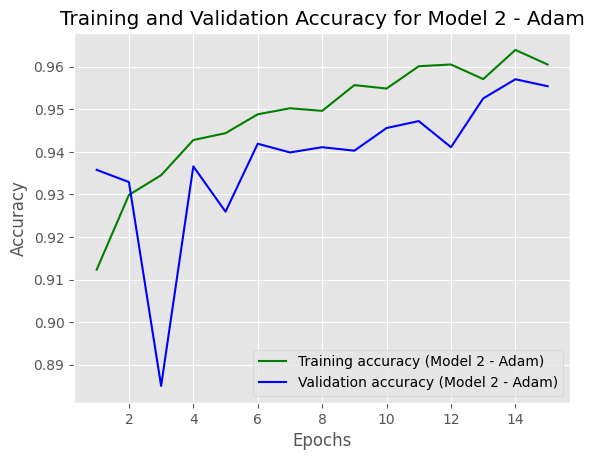

In [44]:
# Get the training and validation accuracy for Model 2 with Adam optimizer
acc_train_model2_adam = history_adam2.history['accuracy']
acc_val_model2_adam = history_adam2.history['val_accuracy']
epochs = range(1, 16)

# Plot the training and validation accuracy for Model 2 with Adam optimizer
plt.plot(epochs, acc_train_model2_adam, 'g', label='Training accuracy (Model 2 - Adam)')
plt.plot(epochs, acc_val_model2_adam, 'b', label='Validation accuracy (Model 2 - Adam)')
plt.title('Training and Validation Accuracy for Model 2 - Adam')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


### Comparision between Optimizers for Mode-2

#### Test Accuracy

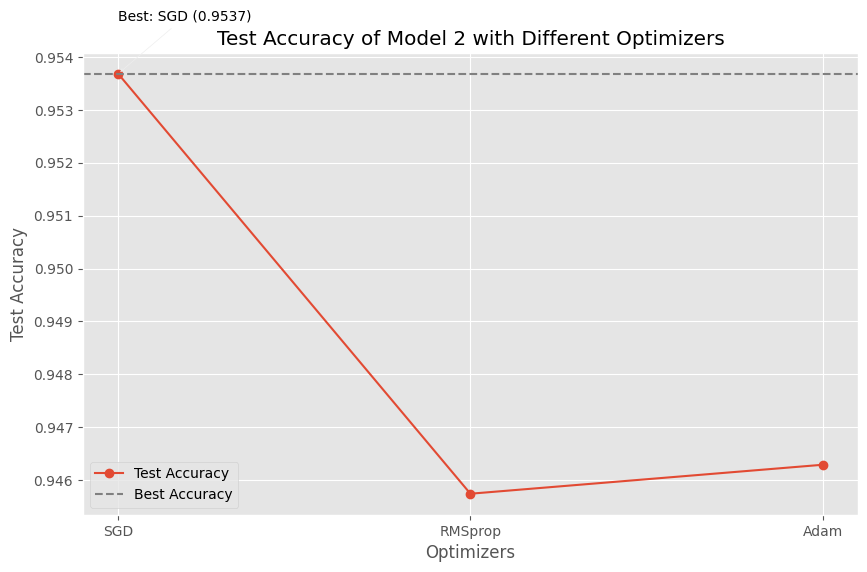

In [47]:
import matplotlib.pyplot as plt

# Test accuracies and optimizers for Model 2
test_accuracies_model2 = [test_accuracy21, test_accuracy22, test_accuracy2_adam]
optimizers_model2 = ['SGD', 'RMSprop', 'Adam']

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(optimizers_model2, test_accuracies_model2, marker='o', linestyle='-', label='Test Accuracy')
plt.axhline(max(test_accuracies_model2), color='gray', linestyle='--', label='Best Accuracy')

# Annotate the optimizer with the highest test accuracy
best_optimizer_index = test_accuracies_model2.index(max(test_accuracies_model2))
best_optimizer = optimizers_model2[best_optimizer_index]
best_accuracy = test_accuracies_model2[best_optimizer_index]
offset = 0.001  # Adjust the offset as needed
plt.annotate(f'Best: {best_optimizer} ({best_accuracy:.4f})',
             xy=(best_optimizer, best_accuracy),
             xytext=(best_optimizer, best_accuracy + offset),
             arrowprops=dict(facecolor='black', arrowstyle='->', mutation_scale=5))

# Add title and labels
plt.title('Test Accuracy of Model 2 with Different Optimizers')
plt.xlabel('Optimizers')
plt.ylabel('Test Accuracy')
plt.grid(True)
plt.legend()

# Display the plot
plt.show()


#### F1 Score

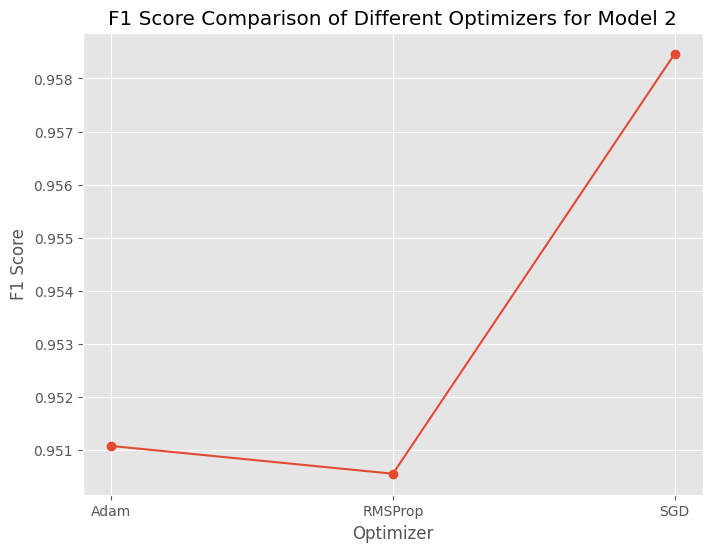

In [48]:
import matplotlib.pyplot as plt

# Optimizers
optimizers_model2 = ['Adam', 'RMSProp', 'SGD']

# F1 scores for Model 2
f1_scores_model2 = [f1_score_adam2, f1_score_rmsprop2, f1_score_sgd2]

# Create line plot
plt.figure(figsize=(8, 6))
plt.plot(optimizers_model2, f1_scores_model2, marker='o', linestyle='-')

# Add labels and title
plt.xlabel('Optimizer')
plt.ylabel('F1 Score')
plt.title('F1 Score Comparison of Different Optimizers for Model 2')

# Show plot
plt.grid(True)
plt.show()


#### ROC AUC Score

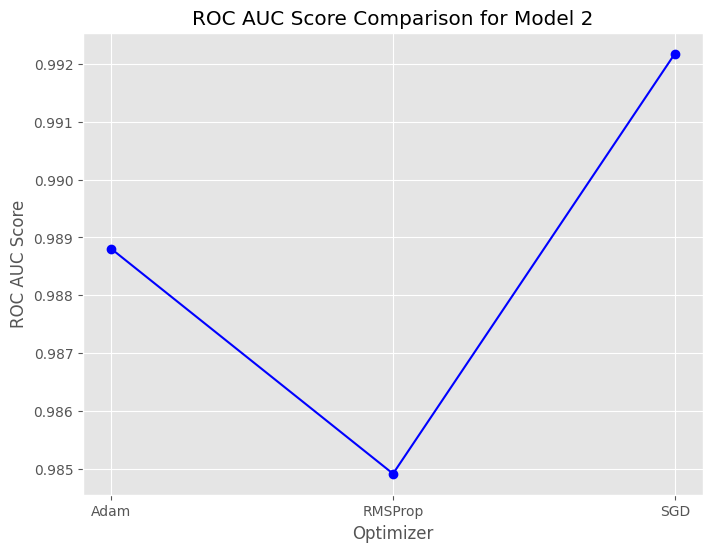

In [49]:
import matplotlib.pyplot as plt

# Define the ROC AUC scores for each optimizer for Model 2
roc_auc_scores_model2 = [roc_auc_adam2, roc_auc_rmsprop2, roc_auc_sgd2]
optimizers_model2 = ['Adam', 'RMSProp', 'SGD']

# Plot ROC AUC scores using a line plot
plt.figure(figsize=(8, 6))
plt.plot(optimizers_model2, roc_auc_scores_model2, marker='o', linestyle='-', color='b')
plt.xlabel('Optimizer')
plt.ylabel('ROC AUC Score')
plt.title('ROC AUC Score Comparison for Model 2')
plt.grid(True)
plt.show()


#### Confusion Matrix

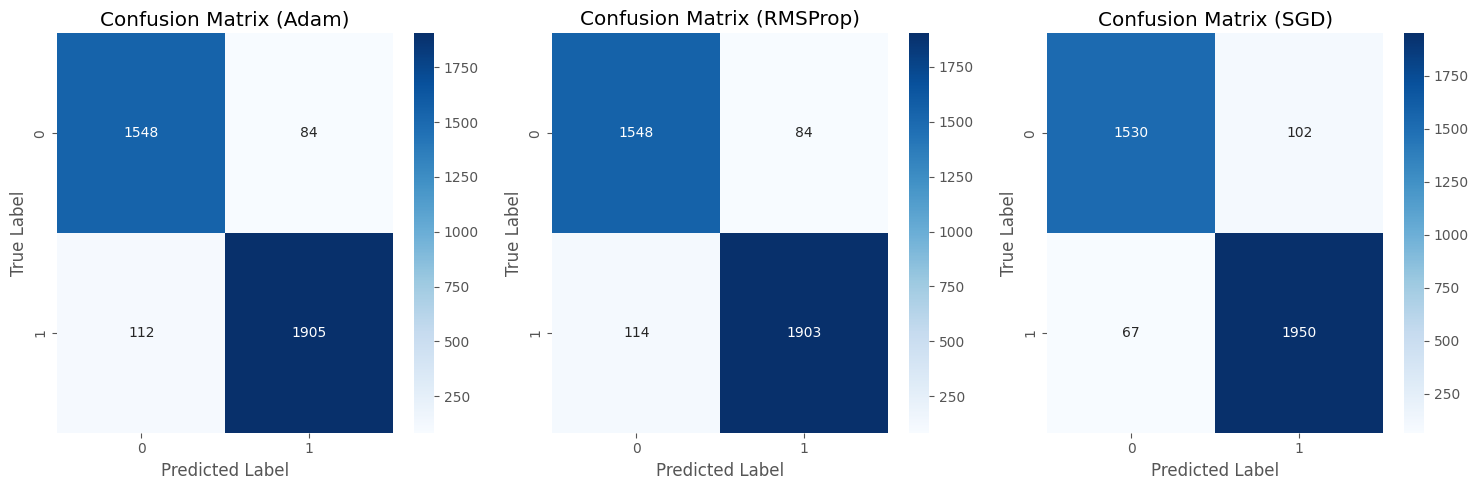

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Define the confusion matrices for each optimizer for Model 2
cms_model2 = [cm_adam2, cm_rmsprop2, cm_sgd2]
optimizers_model2 = ['Adam', 'RMSProp', 'SGD']

# Create subplots for confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Loop through each optimizer and plot its confusion matrix
for i, (cm, optimizer) in enumerate(zip(cms_model2, optimizers_model2)):
    sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', ax=axes[i])
    axes[i].set_title(f'Confusion Matrix ({optimizer})')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()


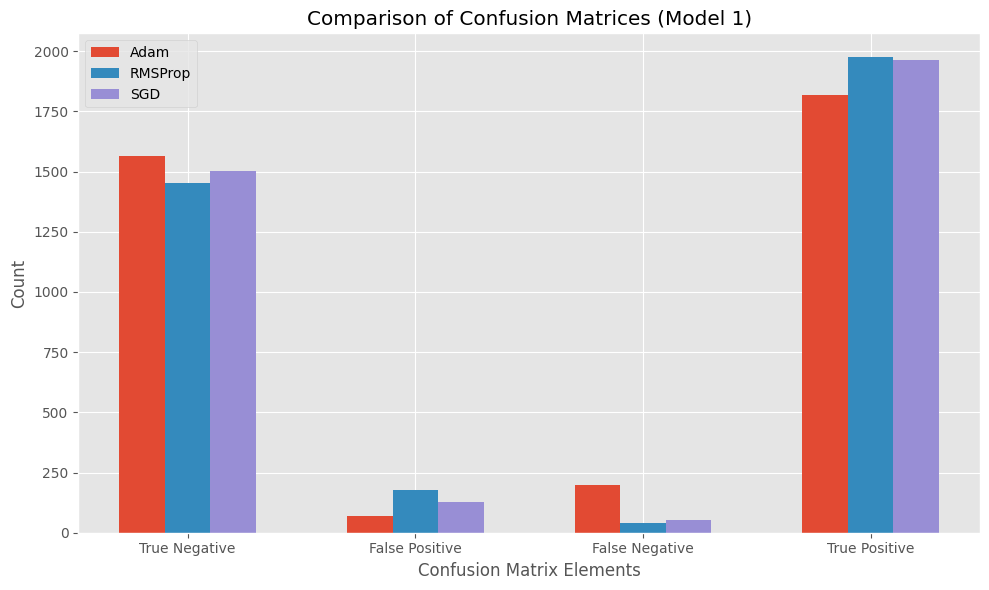

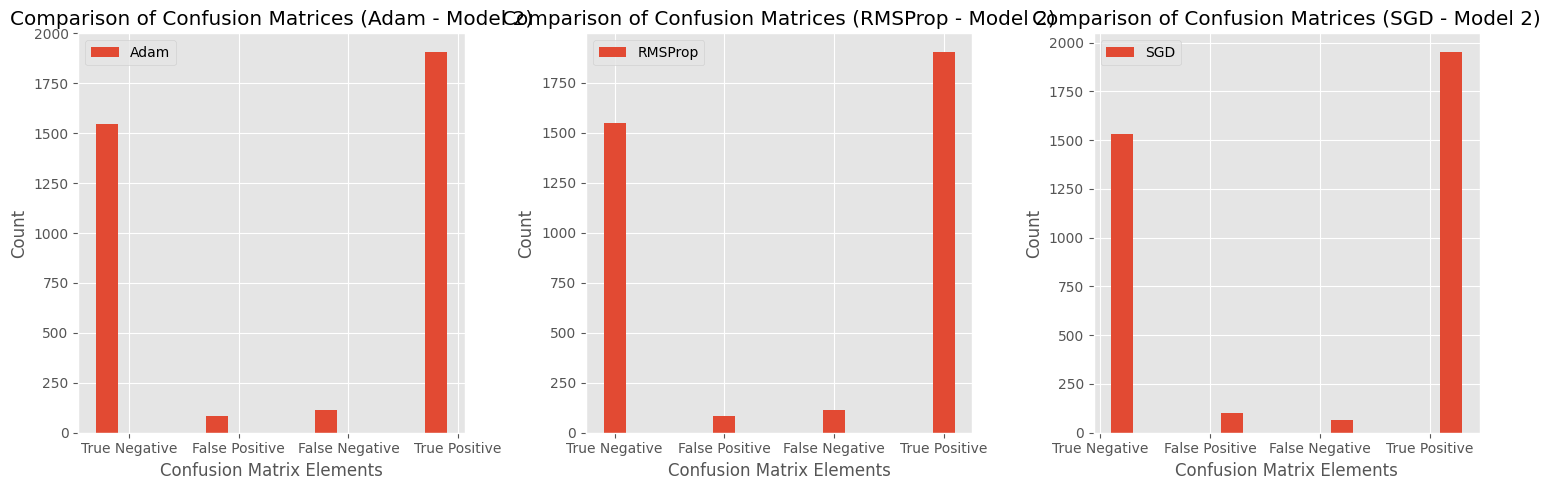

In [51]:
import numpy as np
import matplotlib.pyplot as plt

# Define the confusion matrices for each optimizer for Model 1
cms_model1 = [cm_adam, cm_rmsprop, cm_sgd]
optimizers_model1 = ['Adam', 'RMSProp', 'SGD']

# Define the labels for true and predicted classes
labels = ['True Negative', 'False Positive', 'False Negative', 'True Positive']

# Define the positions for the bars
x = np.arange(len(labels))

# Define the width of the bars
width = 0.2

# Create grouped bar chart for confusion matrices of Model 1
fig, ax = plt.subplots(figsize=(10, 6))

for i, (cm, optimizer) in enumerate(zip(cms_model1, optimizers_model1)):
    ax.bar(x + i * width, cm.flatten(), width=width, label=optimizer)

# Add labels, title, and legend
ax.set_xlabel('Confusion Matrix Elements')
ax.set_ylabel('Count')
ax.set_title('Comparison of Confusion Matrices (Model 1)')
ax.set_xticks(x + width)
ax.set_xticklabels(labels)
ax.legend()

plt.tight_layout()
plt.show()

# Define the confusion matrices for each optimizer for Model 2
cms_model2 = [cm_adam2, cm_rmsprop2, cm_sgd2]
optimizers_model2 = ['Adam', 'RMSProp', 'SGD']

# Create subplots for confusion matrices of Model 2
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Loop through each optimizer and plot its confusion matrix for Model 2
for i, (cm, optimizer) in enumerate(zip(cms_model2, optimizers_model2)):
    axes[i].bar(x + i * width, cm.flatten(), width=width, label=optimizer)
    axes[i].set_xlabel('Confusion Matrix Elements')
    axes[i].set_ylabel('Count')
    axes[i].set_title(f'Comparison of Confusion Matrices ({optimizer} - Model 2)')
    axes[i].set_xticks(x + width)
    axes[i].set_xticklabels(labels)
    axes[i].legend()

plt.tight_layout()
plt.show()


#### Final Conclusion for Model 2

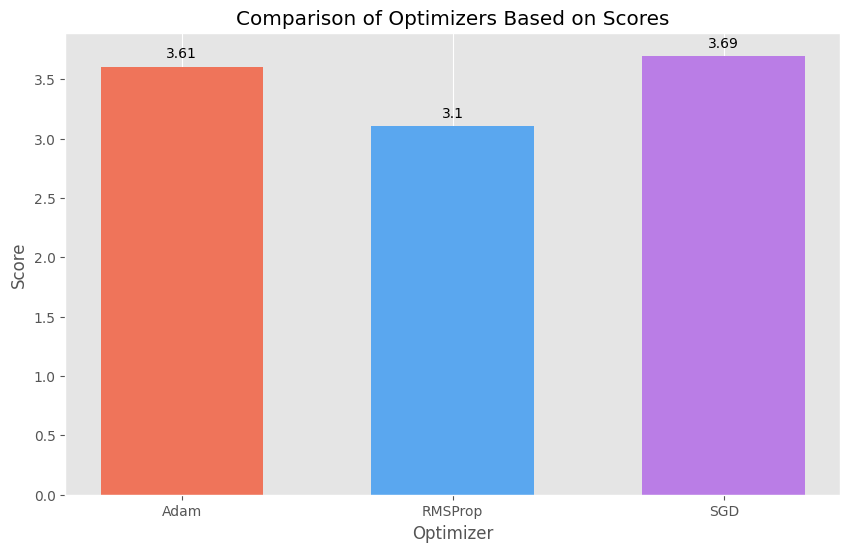

Best Optimizer: SGD


In [52]:
import matplotlib.pyplot as plt

# Define a scoring function
def score_optimizer(accuracy2, f12, roc_auc2, cm2, test_loss2):
    # Normalize confusion matrix values
    normalized_cm2 = cm2 / cm2.sum()

    tp2 = normalized_cm2[1, 1]  # Normalized True Positives
    tn2 = normalized_cm2[0, 0]  # Normalized True Negatives
    fp2 = normalized_cm2[0, 1]  # Normalized False Positives
    fn2 = normalized_cm2[1, 0]  # Normalized False Negatives

    # Compute the score
    score2 = accuracy2 + f12 + roc_auc2 + (tp2 + tn2 - fp2 - fn2) - test_loss2
    return score2

# Compute scores for each optimizer    (remainung)
score_adam2 = score_optimizer(test_accuracy2_adam, f1_score_adam2, roc_auc_adam2, cm_adam2, test_loss2_adam)
score_rmsprop2 = score_optimizer(test_accuracy22, f1_score_rmsprop2, roc_auc_rmsprop2, cm_rmsprop2, test_loss22)
score_sgd2 = score_optimizer(test_accuracy21, f1_score_sgd2, roc_auc_sgd2, cm_sgd2, test_loss21)

# Create a bar plot to compare scores
optimizers2 = ['Adam', 'RMSProp', 'SGD']
scores2 = [score_adam2, score_rmsprop2, score_sgd2]

plt.figure(figsize=(10, 6))
bars = plt.bar(optimizers2, scores2, color=['#EF745A', '#5AA7EF', '#BA7DE6'], width=0.6)  # Reduced width
plt.xlabel('Optimizer')
plt.ylabel('Score')
plt.title('Comparison of Optimizers Based on Scores')
plt.ylim(0, max(scores2) + 0.2)  # Set y-axis limit
plt.grid(axis='y')

# Add text labels on top of each bar
for bar, score2 in zip(bars, scores2):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05, round(score2, 2),
             ha='center', va='bottom')

plt.show()

# Choose the optimizer with the highest score
best_optimizer2 = optimizers2[scores2.index(max(scores2))]
print("Best Optimizer:", best_optimizer2)


### Comparision of SGD for both Models

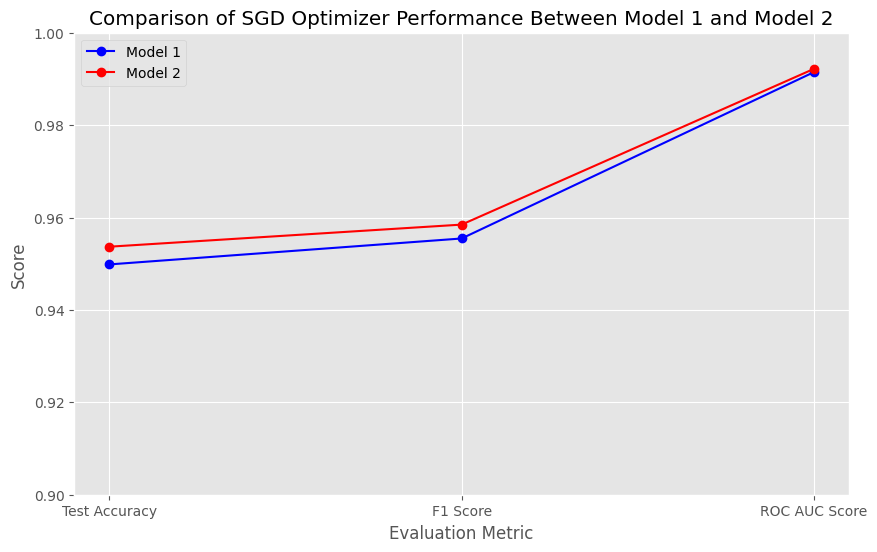

In [53]:
import matplotlib.pyplot as plt

# Evaluation Metrics for Model 1
test_metrics_model1 = [test_accuracy1, f1_score_sgd, roc_auc_sgd]
metric_names = ['Test Accuracy', 'F1 Score', 'ROC AUC Score']

# Evaluation Metrics for Model 2
test_metrics_model2 = [test_accuracy21, f1_score_sgd2, roc_auc_sgd2]

# Plotting
plt.figure(figsize=(10, 6))

# Plot Model 1
plt.plot(metric_names, test_metrics_model1, marker='o', color='b', label='Model 1')

# Plot Model 2
plt.plot(metric_names, test_metrics_model2, marker='o', color='r', label='Model 2')

plt.xlabel('Evaluation Metric')
plt.ylabel('Score')
plt.title('Comparison of SGD Optimizer Performance Between Model 1 and Model 2')
plt.legend()
plt.grid(True)
plt.ylim(0.9, 1)  # Adjust scale as needed
plt.show()





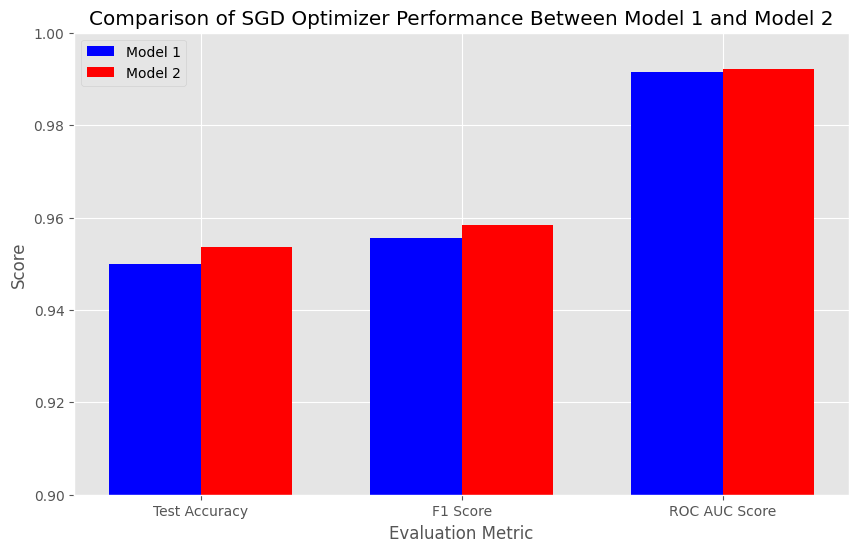

In [64]:
import matplotlib.pyplot as plt

# Evaluation Metrics for Model 1
test_metrics_model1 = [test_accuracy1, f1_score_sgd, roc_auc_sgd]
metric_names = ['Test Accuracy', 'F1 Score', 'ROC AUC Score']

# Evaluation Metrics for Model 2
test_metrics_model2 = [test_accuracy21, f1_score_sgd2, roc_auc_sgd2]

# Plotting
plt.figure(figsize=(10, 6))
bar_width = 0.35
index = range(len(metric_names))

plt.bar(index, test_metrics_model1, bar_width, label='Model 1', color='b')
plt.bar([i + bar_width for i in index], test_metrics_model2, bar_width, label='Model 2', color='r')

plt.xlabel('Evaluation Metric')
plt.ylabel('Score')
plt.title('Comparison of SGD Optimizer Performance Between Model 1 and Model 2')
plt.xticks([i + bar_width/2 for i in index], metric_names)
plt.legend()
plt.grid(True)
plt.ylim(0.9, 1)  # Adjust scale as needed
plt.show()


### Comparision of RMSProp for both Models

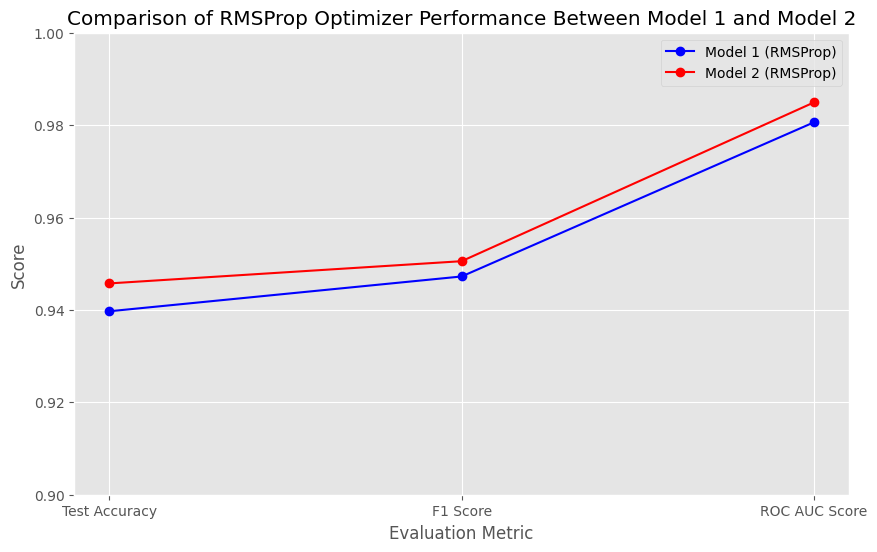

In [55]:
import matplotlib.pyplot as plt

# Evaluation Metrics for Model 1 with RMSProp optimizer
test_metrics_model1_rmsprop = [test_accuracy2, f1_score_rmsprop, roc_auc_rmsprop]
metric_names = ['Test Accuracy', 'F1 Score', 'ROC AUC Score']

# Evaluation Metrics for Model 2 with RMSProp optimizer
test_metrics_model2_rmsprop = [test_accuracy22, f1_score_rmsprop2, roc_auc_rmsprop2]

# Plotting
plt.figure(figsize=(10, 6))

# Plot Model 1 with RMSProp
plt.plot(metric_names, test_metrics_model1_rmsprop, marker='o', color='b', label='Model 1 (RMSProp)')

# Plot Model 2 with RMSProp
plt.plot(metric_names, test_metrics_model2_rmsprop, marker='o', color='r', label='Model 2 (RMSProp)')

plt.xlabel('Evaluation Metric')
plt.ylabel('Score')
plt.title('Comparison of RMSProp Optimizer Performance Between Model 1 and Model 2')
plt.legend()
plt.grid(True)
plt.ylim(0.9, 1)  # Adjust scale as needed
plt.show()


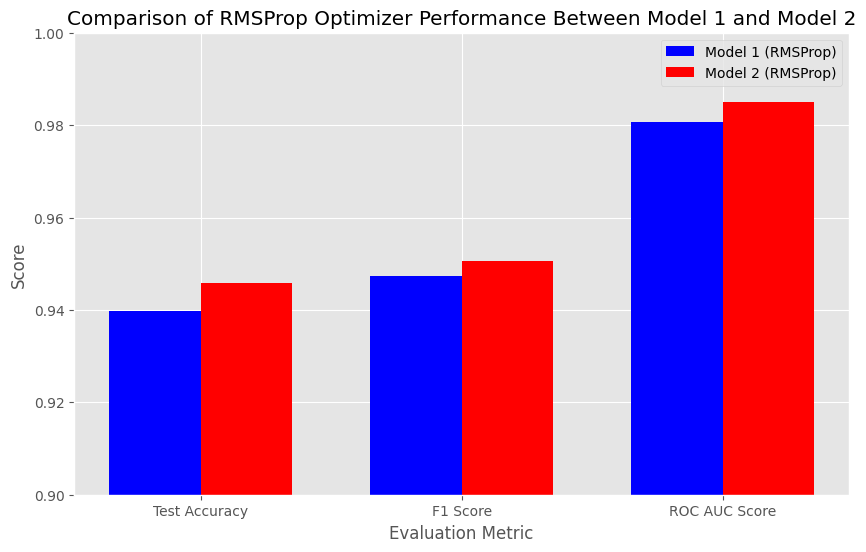

In [56]:
import numpy as np
import matplotlib.pyplot as plt

# Evaluation Metrics for Model 1 with RMSProp optimizer
test_metrics_model1_rmsprop = [test_accuracy2, f1_score_rmsprop, roc_auc_rmsprop]
metric_names = ['Test Accuracy', 'F1 Score', 'ROC AUC Score']

# Evaluation Metrics for Model 2 with RMSProp optimizer
test_metrics_model2_rmsprop = [test_accuracy22, f1_score_rmsprop2, roc_auc_rmsprop2]

# Define the width of the bars
bar_width = 0.35

# Define the positions for the bars
index = np.arange(len(metric_names))

# Plotting
plt.figure(figsize=(10, 6))

# Plot Model 1 with RMSProp
plt.bar(index, test_metrics_model1_rmsprop, bar_width, label='Model 1 (RMSProp)', color='b')

# Plot Model 2 with RMSProp
plt.bar(index + bar_width, test_metrics_model2_rmsprop, bar_width, label='Model 2 (RMSProp)', color='r')

plt.xlabel('Evaluation Metric')
plt.ylabel('Score')
plt.title('Comparison of RMSProp Optimizer Performance Between Model 1 and Model 2')
plt.xticks(index + bar_width / 2, metric_names)
plt.legend()
plt.grid(True)
plt.ylim(0.9, 1)  # Adjust scale as needed
plt.show()


### Comparision of Adam for both Models

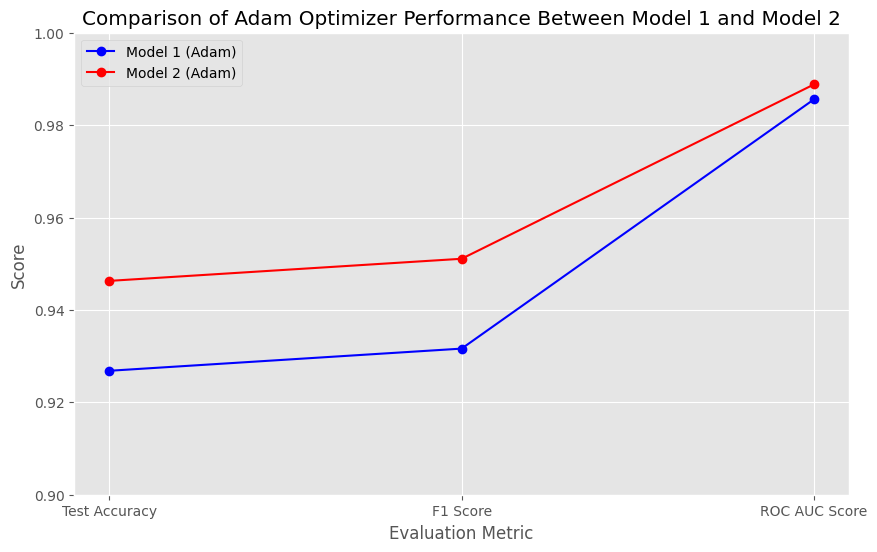

In [57]:
import matplotlib.pyplot as plt

# Evaluation Metrics for Model 1 with Adam optimizer
test_metrics_model1_adam = [test_accuracy3, f1_score_adam, roc_auc_adam]
metric_names = ['Test Accuracy', 'F1 Score', 'ROC AUC Score']

# Evaluation Metrics for Model 2 with Adam optimizer
test_metrics_model2_adam = [test_accuracy2_adam, f1_score_adam2, roc_auc_adam2]

# Plotting
plt.figure(figsize=(10, 6))

# Plot Model 1 with Adam
plt.plot(metric_names, test_metrics_model1_adam, marker='o', color='b', label='Model 1 (Adam)')

# Plot Model 2 with Adam
plt.plot(metric_names, test_metrics_model2_adam, marker='o', color='r', label='Model 2 (Adam)')

plt.xlabel('Evaluation Metric')
plt.ylabel('Score')
plt.title('Comparison of Adam Optimizer Performance Between Model 1 and Model 2')
plt.legend()
plt.grid(True)
plt.ylim(0.9, 1)  # Adjust scale as needed
plt.show()


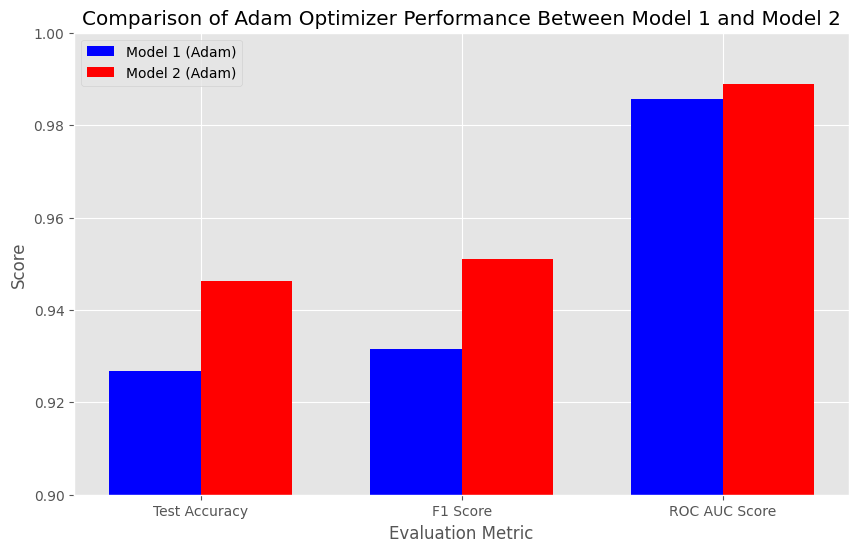

In [58]:
import numpy as np
import matplotlib.pyplot as plt

# Evaluation Metrics for Model 1 with Adam optimizer
test_metrics_model1_adam = [test_accuracy3, f1_score_adam, roc_auc_adam]
metric_names = ['Test Accuracy', 'F1 Score', 'ROC AUC Score']

# Evaluation Metrics for Model 2 with Adam optimizer
test_metrics_model2_adam = [test_accuracy2_adam, f1_score_adam2, roc_auc_adam2]

# Define the width of the bars
bar_width = 0.35

# Define the positions for the bars
index = np.arange(len(metric_names))

# Plotting
plt.figure(figsize=(10, 6))

# Plot Model 1 with Adam
plt.bar(index, test_metrics_model1_adam, bar_width, label='Model 1 (Adam)', color='b')

# Plot Model 2 with Adam
plt.bar(index + bar_width, test_metrics_model2_adam, bar_width, label='Model 2 (Adam)', color='r')

plt.xlabel('Evaluation Metric')
plt.ylabel('Score')
plt.title('Comparison of Adam Optimizer Performance Between Model 1 and Model 2')
plt.xticks(index + bar_width / 2, metric_names)
plt.legend()
plt.grid(True)
plt.ylim(0.9, 1)  # Adjust scale as needed
plt.show()


## Model Enhancement with TDLHBA hyperparameters and visualization

In [59]:
# Imports
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam

model_TDLHBA = Sequential()

model_TDLHBA.add(Dense(40, activation='relu',
          kernel_initializer='uniform',input_dim=30))
model_TDLHBA.add(Dense(30, activation='relu',
          kernel_initializer='uniform'))
model_TDLHBA.add(Dense(1,  activation='sigmoid',
          kernel_initializer='uniform'))

adam = Adam(learning_rate=0.0017470)  # Use learning_rate instead of lr
model_TDLHBA.compile(loss='binary_crossentropy', optimizer=adam, metrics=['accuracy'])


In [60]:
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix

history_TDLHBA = model_TDLHBA.fit(X_train, y_train, batch_size=10, epochs=100, verbose=1)




# Evaluate Model TDLHBA on test data with Adam optimizer
test_loss_TDLHBA, test_accuracy_TDLHBA = model_TDLHBA.evaluate(X_test, y_test)

# Predict labels for test data using Model TDLHBA with Adam optimizer
y_pred_TDLHBA = model_TDLHBA.predict(X_test)
y_pred_binary_TDLHBA = (y_pred_TDLHBA > 0.5).astype(int)

# Calculate F1 score for Model TDLHBA with Adam optimizer
f1_score_TDLHBA = f1_score(y_test, y_pred_binary_TDLHBA)

# Calculate ROC AUC score for Model TDLHBA with Adam optimizer
roc_auc_TDLHBA = roc_auc_score(y_test, y_pred_TDLHBA)

# Calculate confusion matrix for Model TDLHBA with Adam optimizer
cm_TDLHBA = confusion_matrix(y_test, y_pred_binary_TDLHBA)



# Fit the model and evaluate accuracy
history_TDLHBA = model_TDLHBA.fit(X_train, y_train, batch_size=10, epochs=100, verbose=1, callbacks=[es_cb])
scores_TDLHBA = model_TDLHBA.evaluate(X_test, y_test)

# Print evaluation metrics for Model TDLHBA with Adam optimizer
print("Test Loss (Model TDLHBA - Adam):", test_loss_TDLHBA)
print("Test Accuracy (Model TDLHBA - Adam):", test_accuracy_TDLHBA)
print("F1 Score (Model TDLHBA - Adam):", f1_score_TDLHBA)
print("ROC AUC Score (Model TDLHBA - Adam):", roc_auc_TDLHBA)
print("Confusion Matrix (Model TDLHBA - Adam):\n", cm_TDLHBA)


Epoch 1/100
497/497 [==============================] - 3s 3ms/step - loss: 0.2570 - accuracy: 0.8984
Epoch 2/100
497/497 [==============================] - 1s 3ms/step - loss: 0.1811 - accuracy: 0.9277
Epoch 3/100
497/497 [==============================] - 1s 2ms/step - loss: 0.1654 - accuracy: 0.9321
Epoch 4/100
497/497 [==============================] - 1s 2ms/step - loss: 0.1536 - accuracy: 0.9391
Epoch 5/100
497/497 [==============================] - 1s 2ms/step - loss: 0.1428 - accuracy: 0.9444
Epoch 6/100
497/497 [==============================] - 1s 2ms/step - loss: 0.1339 - accuracy: 0.9458
Epoch 7/100
497/497 [==============================] - 1s 2ms/step - loss: 0.1300 - accuracy: 0.9470
Epoch 8/100
497/497 [==============================] - 1s 2ms/step - loss: 0.1204 - accuracy: 0.9516
Epoch 9/100
497/497 [==============================] - 1s 2ms/step - loss: 0.1188 - accuracy: 0.9530
Epoch 10/100
497/497 [==============================] - 1s 2ms/step - loss: 0.1125 - accura

In [61]:
# Define a scoring function
def score_optimizer(accuracy, f1_score, roc_auc, cm, test_loss):
    # Normalize confusion matrix values
    normalized_cm = cm / cm.sum()

    tp = normalized_cm[1, 1]  # Normalized True Positives
    tn = normalized_cm[0, 0]  # Normalized True Negatives
    fp = normalized_cm[0, 1]  # Normalized False Positives
    fn = normalized_cm[1, 0]  # Normalized False Negatives

    # Compute the score
    score = accuracy + f1_score + roc_auc + (tp + tn - fp - fn) - test_loss
    return score

# Compute scores for the Adam optimizer for Model TDLHBA
score_adam_TDLHBA = score_optimizer(test_accuracy_TDLHBA, f1_score_TDLHBA, roc_auc_TDLHBA, cm_TDLHBA, test_loss_TDLHBA)


In [62]:
# Define scores for Model 1 across different optimizers
scores_model1 = {
    'Adam': score_adam,
    'RMSProp': score_rmsprop,
    'SGD': score_sgd
}

# Define scores for Model 2 across different optimizers
scores_model2 = {
    'Adam': score_adam2,
    'RMSProp': score_rmsprop2,
    'SGD': score_sgd2
}

# Define the score for Model TDLHBA
score_TDLHBA = score_adam_TDLHBA

# Print and compare the scores
print("Scores for Model 1:")
for optimizer, score in scores_model1.items():
    print(f"{optimizer}: {score}")
print()

print("Scores for Model 2:")
for optimizer, score in scores_model2.items():
    print(f"{optimizer}: {score}")
print()

print("Score for Model TDLHBA:")
print(score_TDLHBA)


Scores for Model 1:
Adam: 3.4410801393738026
RMSProp: 3.1785110368253293
SGD: 3.66754775447908

Scores for Model 2:
Adam: 3.606104470332463
RMSProp: 3.104166193649605
SGD: 3.6916564838089623

Score for Model TDLHBA:
3.611727131055371


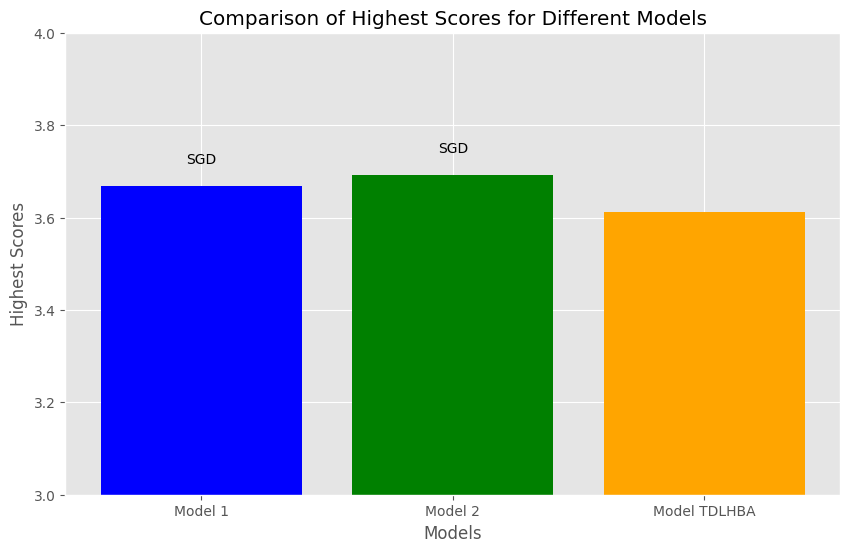

In [63]:
import matplotlib.pyplot as plt

# Find the optimizer with the highest score for Model 1
best_optimizer_model1 = max(scores_model1, key=scores_model1.get)
highest_score_model1 = scores_model1[best_optimizer_model1]

# Find the optimizer with the highest score for Model 2
best_optimizer_model2 = max(scores_model2, key=scores_model2.get)
highest_score_model2 = scores_model2[best_optimizer_model2]

# Find the optimizer with the highest score for Model TDLHBA
best_optimizer_TDLHBA = ''  # Since there's only one optimizer
highest_score_TDLHBA = score_TDLHBA

# Create a bar plot to compare the highest scores
models = ['Model 1', 'Model 2', 'Model TDLHBA']
optimizer_names = [best_optimizer_model1, best_optimizer_model2, best_optimizer_TDLHBA]
highest_scores = [highest_score_model1, highest_score_model2, highest_score_TDLHBA]

plt.figure(figsize=(10, 6))
plt.bar(models, highest_scores, color=['blue', 'green', 'orange'])
plt.xlabel('Models')
plt.ylabel('Highest Scores')
plt.title('Comparison of Highest Scores for Different Models')
for i in range(len(models)):
    plt.text(i, highest_scores[i] + 0.05, f'{optimizer_names[i]}', ha='center')
plt.ylim(3, 4)  # Set y-axis limit
plt.show()

